# Sparse Autoencoder on GPT-2 Small

**Task source:**  this notebook covers only the SAE part: train and evaluate a small SAE on frozen GPT-2 Small activations.

| Required item | Cell | Evidence |
|---|---|---|
| Collect 10,000-20,000 activation vectors from one fixed site, padding removed, train/held-out split before extraction, provenance saved | 2, 3, 11 | 13,103 train + 3,276 held-out vectors (208 / 52 passages) |
| Site: block-6 post-residual | 2, 3 | hidden_states[7] = blocks.6.hook_resid_post (convention to be confirmed with the mentor) |
| Consistent activation scaling | 4 | scale 0.3121 fit on training data only |
| SAE with 1,024 latents, MSE + L1 loss, decoder norm constraint | 5 | 1,574,656 trainable parameters |
| Implementation correctness | 6 | gradient check max relative error 5.46e-09 |
| Two SAEs: same setup, low/high penalty, 300-600 steps, curves, checkpoints | 7, 8, 10, 11 | lambda 0.0003 and 0.003, 500 steps, batch 128 |
| Held-out evaluation: MSE, L0 with threshold, never-active %, mean baseline | 8, 8b | table in Cell 8 |
| Inspect 2-3 latents and test descriptions on new text | 8c, 9, 9b | latents 428, 685, 449 |
| Trade-off figure and explanation | 10, 12 | four-panel figure; report draft |
| Deliverables: notebook, saved outputs, report, reproducibility record | 11, 12, 13 | outputs_small.zip, report_draft.md |

## Cell 1: Setup and constants
**Purpose:** import libraries and fix the constants used everywhere.
**What it does:** imports NumPy, matplotlib and standard tools; sets SEED = 0, D_MODEL = 768 (GPT-2 Small residual width) and N_LATENTS = 1024 (assignment default dictionary size); seeds NumPy.
**Requirement covered:** reproducibility (fixed seed) and the 1,024-latent default.
**Output:** none.

In [1]:
import json, os, time, platform
import numpy as np
import matplotlib.pyplot as plt

SEED = 0
D_MODEL = 768            # GPT-2 Small residual-stream width
N_LATENTS = 1024         # dictionary size (assignment default)
np.random.seed(SEED)

## Cell 2: Load frozen GPT-2 Small and WikiText-2, split by passage
**Purpose:** get the model and the text, and create the train/held-out split before any activation exists.
**What it does:**
1. Loads GPT-2 Small (`gpt2`) in evaluation mode and turns off gradients for all its parameters (the model stays frozen).
2. Sets the site (SITE_LAYER = 6, i.e. `blocks.6.hook_resid_post`, which is Hugging Face `hidden_states[7]`), 64 tokens per passage, 260 passages, and excludes token position 0.
3. Loads WikiText-2 (raw, train split) from `Salesforce/wikitext` (with a fallback that reads the data file directly), keeps paragraphs longer than 300 characters that are not headings, picks 260 at random with a fixed seed.
4. Splits 80/20 **by passage** into train and held-out texts.
**Requirement covered:** ordinary varied text; split before extraction; frozen model in eval mode.
**Output (measured):** 13,290 usable passages; 208 train and 52 held-out passages.

In [2]:
!pip install -q transformers datasets
import torch
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
from datasets import load_dataset

device = "cuda" if torch.cuda.is_available() else "cpu"
tok = GPT2TokenizerFast.from_pretrained("gpt2")
tok.pad_token = tok.eos_token
lm = GPT2LMHeadModel.from_pretrained("gpt2").to(device).eval()      # frozen, evaluation mode
for p in lm.parameters():
    p.requires_grad_(False)

SITE_LAYER = 6          # block index 6 (zero-based) = TransformerLens "blocks.6.hook_resid_post"
MAX_TOK = 64            # tokens kept per passage
N_PASSAGES = 260        # about 260 x 63 = 16,000 vectors (fallback: 120)
EXCLUDE_FIRST = True    # drop token position 0 (see the check in Cell 3)

try:
    raw = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
    all_lines = raw["text"]
except Exception as e:                                    # fallback: read the data file directly
    print("load_dataset failed:", repr(e)[:200], "-> reading the parquet file directly")
    from huggingface_hub import hf_hub_download
    import pandas as pd
    path = hf_hub_download(repo_id="Salesforce/wikitext",
                           filename="wikitext-2-raw-v1/train-00000-of-00001.parquet",
                           repo_type="dataset")
    all_lines = pd.read_parquet(path)["text"].tolist()

texts = [t.strip() for t in all_lines if len(t.strip()) > 300 and not t.strip().startswith("=")]
print(len(texts), "usable passages")
order = np.random.default_rng(SEED).permutation(len(texts))[:N_PASSAGES]
texts = [texts[i] for i in order]
n_train_p = int(0.8 * len(texts))
train_texts, heldout_texts = texts[:n_train_p], texts[n_train_p:]   # split by PASSAGE, before any activation exists
print(len(train_texts), "train passages |", len(heldout_texts), "held-out passages")

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

13290 usable passages
208 train passages | 52 held-out passages


## Cell 3: Extract and cache activations at the fixed site
**Purpose:** turn the passages into activation vectors and record where each came from.
**What it does:**
- `collect_batch` removes padding positions, drops token position 0, and records for every vector its passage id and token position, plus the token ids of each passage.
- `extract` runs GPT-2 in batches with gradients off and reads `hidden_states[7]`, then calls `collect_batch`. Language-model forward passes are therefore separate from SAE training.
- A check compares activation norms at position 0 with later positions, to justify excluding position 0.
**Requirement covered:** experiment 1 (about 10,000-20,000 vectors, padding removed, provenance kept).
**Output (measured):** train vectors (13103, 768); held-out vectors (3276, 768); mean norm at position 0 = 3034.4 vs 88.9 at positions 1+ (measured on 16 training passages). Position 0 is about 34 times larger, so it would dominate the squared error; it was excluded.

In [3]:
def collect_batch(h, ids, mask, first_pass_id, exclude_first=True):
    """h: (B,T,d) activations, ids: (B,T) token ids, mask: (B,T) with 1 = real token, 0 = padding.
    Returns the activation vectors, their passage ids, token positions, and the token ids of each passage."""
    acts, pass_ids, positions, token_lists = [], [], [], []
    for i in range(h.shape[0]):
        n = int(mask[i].sum())                       # number of real tokens (padding is dropped)
        token_lists.append(ids[i, :n].tolist())
        start = 1 if exclude_first else 0            # position 0 handled by an explicit rule
        acts.append(h[i, start:n])
        pass_ids += [first_pass_id + i] * (n - start)
        positions += list(range(start, n))
    return np.concatenate(acts), np.array(pass_ids), np.array(positions), token_lists


def extract(passages, batch_lm=16):
    A, P, S, T = [], [], [], []
    for b in range(0, len(passages), batch_lm):
        enc = tok(passages[b:b + batch_lm], return_tensors="pt", padding=True, truncation=True, max_length=MAX_TOK)
        enc = {k: v.to(device) for k, v in enc.items()}
        with torch.no_grad():                                           # no gradients: we only read activations
            hs = lm(**enc, output_hidden_states=True).hidden_states[SITE_LAYER + 1]
        a, pid, ps, toks = collect_batch(hs.float().cpu().numpy(), enc["input_ids"].cpu().numpy(),
                                         enc["attention_mask"].cpu().numpy(), len(T), EXCLUDE_FIRST)
        A.append(a); P.append(pid); S.append(ps); T += toks
    return np.concatenate(A), np.concatenate(P), np.concatenate(S), T


A_train, P_train, S_train, T_train = extract(train_texts)
A_ho, P_ho, S_ho, T_ho = extract(heldout_texts)
print("train vectors:", A_train.shape, "| held-out vectors:", A_ho.shape)

# check behind the EXCLUDE_FIRST choice: how large are activations at position 0 compared with the others?
enc = tok(train_texts[:16], return_tensors="pt", padding=True, truncation=True, max_length=MAX_TOK)
enc = {k: v.to(device) for k, v in enc.items()}
with torch.no_grad():
    h0 = lm(**enc, output_hidden_states=True).hidden_states[SITE_LAYER + 1].float().cpu().numpy()
nrm = np.linalg.norm(h0, axis=-1)
print("mean activation norm at position 0:", nrm[:, 0].mean().round(1), "| at positions 1+:", nrm[:, 1:].mean().round(1))

train vectors: (13103, 768) | held-out vectors: (3276, 768)
mean activation norm at position 0: 3034.4 | at positions 1+: 88.9


## Cell 4: Scale the activations (fit on training data only)
**Purpose:** put activations on a fixed, consistent scale for both SAE runs.
**What it does:** computes one scalar so the mean training vector norm becomes sqrt(768) = 27.71, and applies the same scalar to the held-out vectors. Nothing is fitted on held-out data.
**Requirement covered:** consistent activation scaling; the "stated normalization" for MSE (all MSE values are in these scaled units).
**Output (measured):** scale 0.3121; mean norm train 27.71, held-out 27.79.

In [4]:
scale = np.sqrt(D_MODEL) / np.linalg.norm(A_train, axis=1).mean()   # average vector norm becomes sqrt(768)
Xtr = (A_train * scale).astype(np.float32)
Xho = (A_ho * scale).astype(np.float32)                              # the SAME scale, taken from training data
print("scale:", scale, "| mean norm train:", np.linalg.norm(Xtr, axis=1).mean().round(2),
      "| held-out:", np.linalg.norm(Xho, axis=1).mean().round(2))

scale: 0.3120692041211135 | mean norm train: 27.71 | held-out: 27.79


## Cell 5: The sparse autoencoder and the optimizer (NumPy)
**Purpose:** define the model and its training algorithm.
**What it does:**
- Encoder: f = ReLU((x - b_dec) W_enc + b_enc). Decoder: x_hat = f W_dec + b_dec. 1,024 latents, 1,574,656 trainable parameters.
- Loss: (1/768)||x - x_hat||^2 + lambda ||f||_1, each averaged over the batch.
- Hand-written gradients for all four parameter groups (the L1 term contributes lambda/B on active latents; b_dec appears in the decoder and in the centred input).
- `normalize_decoder` rescales every decoder row to unit length (closes the scale loophole in the L1 penalty).
- Adam optimizer. Same initialization seed gives identical starting weights, as required for the two-run comparison.
**Matrix convention:** W_enc is (768 x 1024) and W_dec is (1024 x 768) because examples are rows; this is the assignment's math transposed.
**Output:** none.

In [5]:
class SparseAutoencoder:
    """f = ReLU((x - b_dec) @ W_enc + b_enc)      x_hat = f @ W_dec + b_dec
    Rows of W_dec are the feature directions and are kept at unit length."""
    def __init__(self, d, K, init_seed=0, b_dec_init=None, dtype=np.float32):
        rng = np.random.default_rng(init_seed)
        W_dec = rng.standard_normal((K, d))
        W_dec /= np.linalg.norm(W_dec, axis=1, keepdims=True)
        self.p = {"W_enc": W_dec.T.copy().astype(dtype),                  # (d, K), starts as the transpose of the decoder
                  "b_enc": np.zeros(K, dtype=dtype),
                  "W_dec": W_dec.astype(dtype),                           # (K, d)
                  "b_dec": (np.zeros(d) if b_dec_init is None else np.asarray(b_dec_init)).astype(dtype)}

    def encode(self, x):
        return np.maximum(0, (x - self.p["b_dec"]) @ self.p["W_enc"] + self.p["b_enc"])

    def decode(self, f):
        return f @ self.p["W_dec"] + self.p["b_dec"]

    def loss(self, x, lam):
        f = self.encode(x); x_hat = self.decode(f)
        mse = np.mean(((x - x_hat) ** 2).sum(1) / x.shape[1])             # (1/d)||x - x_hat||^2, averaged over the batch
        l1 = np.mean(np.abs(f).sum(1))                                    # ||f||_1, averaged over the batch
        return mse + lam * l1, mse, l1

    def grads(self, x, lam):
        B, d = x.shape
        xc = x - self.p["b_dec"]
        pre = xc @ self.p["W_enc"] + self.p["b_enc"]
        f = np.maximum(0, pre)
        x_hat = f @ self.p["W_dec"] + self.p["b_dec"]
        d_xhat = (2.0 / (d * B)) * (x_hat - x)                            # d loss / d x_hat
        d_f = d_xhat @ self.p["W_dec"].T + lam / B                        # reconstruction path + L1 path (f >= 0, so |f| = f)
        d_pre = d_f * (pre > 0)                                           # ReLU derivative
        g = {"W_dec": f.T @ d_xhat,
             "W_enc": xc.T @ d_pre,
             "b_enc": d_pre.sum(0)}
        g["b_dec"] = d_xhat.sum(0) - (d_pre @ self.p["W_enc"].T).sum(0)  # b_dec appears in the decoder and in the centred input
        return g, f

    def normalize_decoder(self):
        self.p["W_dec"] /= np.linalg.norm(self.p["W_dec"], axis=1, keepdims=True) + 1e-12   # scale-loophole fix


class Adam:
    def __init__(self, lr=1e-3, b1=0.9, b2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps, self.t, self.v, self.s = lr, b1, b2, eps, 0, {}, {}
    def update(self, params, grads):
        self.t += 1
        for k in params:
            v = self.b1 * self.v.get(k, 0) + (1 - self.b1) * grads[k]
            s = self.b2 * self.s.get(k, 0) + (1 - self.b2) * grads[k] ** 2
            self.v[k], self.s[k] = v, s
            params[k] -= (self.lr * (v / (1 - self.b1 ** self.t)) / (np.sqrt(s / (1 - self.b2 ** self.t)) + self.eps)).astype(params[k].dtype)

## Cell 6: Gradient check
**Purpose:** prove the SAE gradients are right before training.
**What it does:** on a tiny random problem, compares each analytical gradient with a numerical one, (J(w+eps) - J(w-eps)) / 2eps, for every parameter, and reports the worst relative error.

**Requirement covered:** correct implementation; the independent check the assignment asks for.

**Output (measured):** max relative error 5.46e-09 (a value around 1e-7 or smaller means the gradients are correct).

In [6]:
def sae_gradient_check(eps=1e-6, seed=1):
    rng = np.random.default_rng(seed)
    x = rng.standard_normal((6, 5))
    sae = SparseAutoencoder(5, 8, init_seed=seed, b_dec_init=rng.standard_normal(5) * 0.1, dtype=np.float64)
    sae.p["b_enc"] += rng.standard_normal(8) * 0.1                        # make the check less trivial
    lam = 0.05
    g, _ = sae.grads(x, lam)
    worst = 0.0
    for name, w in sae.p.items():
        for idx in np.ndindex(*w.shape):
            old = w[idx]
            w[idx] = old + eps; jp = sae.loss(x, lam)[0]
            w[idx] = old - eps; jm = sae.loss(x, lam)[0]
            w[idx] = old
            num = (jp - jm) / (2 * eps)
            den = abs(num) + abs(g[name][idx])
            if den > 1e-10:
                worst = max(worst, abs(num - g[name][idx]) / den)
    return worst

print("max relative error:", f"{sae_gradient_check():.2e}")    # should be about 1e-8 or smaller

max relative error: 5.46e-09


## Cell 7: Training, evaluation and the lambda pilot
**Purpose:** define how to train and measure an SAE, and choose the two sparsity penalties without touching the held-out set.
**What it does:**
- `train_sae`: mini-batch training (shuffled batches, Adam, decoder renormalized after each step); same seeds give the same init and batch order. Logs reconstruction MSE, L1 and active latents (L0, threshold 1e-6) per step.

- `evaluate`: held-out MSE, baseline MSE (always predict the training mean), variance accounted for, mean active latents, and the percentage of latents never active on the evaluation sample.

- `lambda_pilot`: short (150-step) runs of five penalties on TRAINING data only.
**Requirement covered:** experiment 2 (two penalties with a clear contrast) and experiment 3 (metrics).
**Output (measured, training data only; baseline MSE 0.5224):
**
| lambda | active latents (L0) of 1024 | train MSE |
|---|---|---|
| 0.0001 | 580.4 | 0.0698 |
| 0.0003 | 490.9 | 0.0870 |
| 0.001 | 302.0 | 0.1569 |
| 0.003 | 90.1 | 0.3207 |
| 0.01 | 6.9 | 0.5078 |

**Selection rule (fixed before looking at held-out results):** high lambda = the largest value whose training MSE removed at least 30% of the baseline error (0.003 removed 38.6%; 0.01 removed only 2.8%); low lambda = ten times smaller.

In [7]:
def train_sae(X, lam, steps=500, batch=128, lr=1e-3, init_seed=0, data_seed=0, log_every=50):
    sae = SparseAutoencoder(X.shape[1], N_LATENTS, init_seed=init_seed, b_dec_init=X.mean(0))
    opt, rng = Adam(lr), np.random.default_rng(data_seed)                 # same seeds -> same init and same batch order in both runs
    hist = {"step": [], "total": [], "mse": [], "l1": [], "l0": []}
    order, ptr = rng.permutation(len(X)), 0
    for step in range(1, steps + 1):
        if ptr + batch > len(X):
            order, ptr = rng.permutation(len(X)), 0
        xb = X[order[ptr:ptr + batch]]; ptr += batch
        g, f = sae.grads(xb, lam)
        opt.update(sae.p, g)
        sae.normalize_decoder()
        total, mse, l1 = sae.loss(xb, lam)
        hist["step"].append(step); hist["total"].append(float(total)); hist["mse"].append(float(mse))
        hist["l1"].append(float(l1)); hist["l0"].append(float((f > 1e-6).sum(1).mean()))
        if log_every and (step == 1 or step % log_every == 0):
            print(f"lam={lam:<6} step {step:4d} | total {total:.4f} | mse {mse:.4f} | L1 {l1:7.2f} | L0 {hist['l0'][-1]:6.1f}")
    return sae, hist


def evaluate(sae, X, mean_train, thr=1e-6):
    f = sae.encode(X); x_hat = sae.decode(f); d = X.shape[1]
    sq_err = ((X - x_hat) ** 2).sum(1)
    base_err = ((X - mean_train) ** 2).sum(1)                             # baseline: always predict the training mean
    var_total = ((X - X.mean(0)) ** 2).sum()
    freq = (f > thr).mean(0)                                              # fraction of vectors on which each latent is active
    return {"mse": float(sq_err.mean() / d), "baseline_mse": float(base_err.mean() / d),
            "vaf": float(1 - sq_err.sum() / var_total),
            "l0": float((f > thr).sum(1).mean()), "l1": float(np.abs(f).sum(1).mean()),
            "dead_pct": float(100 * (freq == 0).mean()), "n_vectors": int(len(X)), "threshold": thr}


def lambda_pilot(X, lams, steps=150, batch=128, lr=1e-3):
    """Short runs on TRAINING data only; the held-out set is not touched."""
    base_mse = float(np.mean(((X - X.mean(0)) ** 2).sum(1) / X.shape[1]))
    print(f"mean baseline MSE on training data: {base_mse:.4f}")
    for lam in lams:
        sae, h = train_sae(X, lam, steps=steps, batch=batch, lr=lr, init_seed=0, data_seed=0, log_every=0)
        f = sae.encode(X[:2000]); mse = float(np.mean(((X[:2000] - sae.decode(f)) ** 2).sum(1) / X.shape[1]))
        print(f"lambda={lam:<8} train L0={float((f > 1e-6).sum(1).mean()):7.1f} of {N_LATENTS} | "
              f"train MSE={mse:.4f} | better than baseline: {mse < base_mse}")

lambda_pilot(Xtr, [1e-4, 3e-4, 1e-3, 3e-3, 1e-2])

mean baseline MSE on training data: 0.5224
lambda=0.0001   train L0=  580.4 of 1024 | train MSE=0.0698 | better than baseline: True
lambda=0.0003   train L0=  490.9 of 1024 | train MSE=0.0870 | better than baseline: True
lambda=0.001    train L0=  302.0 of 1024 | train MSE=0.1569 | better than baseline: True
lambda=0.003    train L0=   90.1 of 1024 | train MSE=0.3207 | better than baseline: True
lambda=0.01     train L0=    6.9 of 1024 | train MSE=0.5078 | better than baseline: True


## Cell 8: Train the two SAEs and evaluate on held-out activations
**Purpose:** the main experiment: two SAEs that differ only in the sparsity penalty.
**What it does:** trains lambda = 0.0003 and lambda = 0.003 with identical initialization, batch order, 500 steps, batch size 128 and Adam (learning rate 1e-3), then evaluates both on the 3,276 held-out vectors. The held-out set was not used to choose anything.
**Requirement covered:** experiments 2 and 3.
**Output (measured, held-out, active means latent > 1e-6):
**
| | lambda 0.0003 | lambda 0.003 |
|---|---|---|
| MSE | 0.0696 | 0.2610 |
| Mean baseline MSE | 0.5262 | 0.5262 |
| Variance accounted for | 0.867 | 0.503 |
| Active latents (L0) | 543.4 | 53.9 |
| Never-active latents | 0.0% | 0.0% |

**Reading:** a tenfold stronger penalty cut L0 about tenfold and raised MSE about 3.7 times; both runs beat the mean baseline.

In [8]:
LAMS = [3e-4, 3e-3]            # <- replace with the two values you chose from the pilot
STEPS, BATCH, LR = 500, 128, 1e-3          # fallback: STEPS=200, BATCH=64

saes, hists, results = [], [], []
for lam in LAMS:
    s, h = train_sae(Xtr, lam, steps=STEPS, batch=BATCH, lr=LR, init_seed=0, data_seed=0, log_every=100)
    saes.append(s); hists.append(h); results.append(evaluate(s, Xho, Xtr.mean(0)))

import pandas as pd
table = pd.DataFrame(results, index=[f"lambda={l}" for l in LAMS]).round(4)
table["threshold"] = "1e-6"          # the real threshold (rounding to 4 decimals had turned it into 0.0)
print(table)

lam=0.0003 step    1 | total 0.3593 | mse 0.2763 | L1  276.91 | L0  509.8
lam=0.0003 step  100 | total 0.1870 | mse 0.1121 | L1  249.96 | L0  489.1
lam=0.0003 step  200 | total 0.1492 | mse 0.0772 | L1  240.02 | L0  494.4
lam=0.0003 step  300 | total 0.1369 | mse 0.0632 | L1  245.67 | L0  509.1
lam=0.0003 step  400 | total 0.1342 | mse 0.0592 | L1  250.14 | L0  522.8
lam=0.0003 step  500 | total 0.1296 | mse 0.0551 | L1  248.29 | L0  525.8
lam=0.003  step    1 | total 1.0873 | mse 0.2883 | L1  266.35 | L0  509.8
lam=0.003  step  100 | total 0.4715 | mse 0.3716 | L1   33.30 | L0  106.5
lam=0.003  step  200 | total 0.3769 | mse 0.2866 | L1   30.12 | L0   73.3
lam=0.003  step  300 | total 0.3461 | mse 0.2538 | L1   30.79 | L0   62.8
lam=0.003  step  400 | total 0.3348 | mse 0.2409 | L1   31.31 | L0   55.9
lam=0.003  step  500 | total 0.3151 | mse 0.2260 | L1   29.70 | L0   46.2
                  mse  baseline_mse     vaf        l0        l1  dead_pct  \
lambda=0.0003  0.0696        0.5262

## Cell 8b: Train vs held-out error, and sensitivity to the "active" threshold
**Purpose:** check that the reported held-out numbers are not an artifact of one evaluation choice.

**What it does:** compares MSE and variance accounted for on the full training set and on the held-out set for both runs; recomputes L0 and the never-active percentage at thresholds 1e-6, 1e-2 and 1e-1.
**Requirement covered:** experiment 3 (explicit L0 threshold, dead latents on the evaluation sample).

**Output:** the output see below the code. A strict threshold counts tiny activations as active, so a higher threshold may reveal latents that are effectively unused.

In [9]:
def evaluate_thresholds(sae, X, thresholds=(1e-6, 1e-2, 1e-1)):
    f = sae.encode(X); out = {}
    for t in thresholds:
        on = f > t
        out[t] = (round(float(on.sum(1).mean()), 1), round(float(100 * (on.mean(0) == 0).mean()), 1))
    return out

threshold_rows = {}
for lam, s in zip(LAMS, saes):
    tr = evaluate(s, Xtr, Xtr.mean(0)); ho = evaluate(s, Xho, Xtr.mean(0))
    print(f"lambda={lam}: MSE train {tr['mse']:.4f} | MSE held-out {ho['mse']:.4f} | "
          f"VAF train {tr['vaf']:.3f} | VAF held-out {ho['vaf']:.3f}")
    threshold_rows[lam] = evaluate_thresholds(s, Xho)
    for t, (l0, dead) in threshold_rows[lam].items():
        print(f"    held-out, active means > {t}: L0 = {l0} | never-active latents = {dead}%")

lambda=0.0003: MSE train 0.0525 | MSE held-out 0.0696 | VAF train 0.899 | VAF held-out 0.867
    held-out, active means > 1e-06: L0 = 543.4 | never-active latents = 0.0%
    held-out, active means > 0.01: L0 = 535.1 | never-active latents = 0.0%
    held-out, active means > 0.1: L0 = 461.7 | never-active latents = 0.0%
lambda=0.003: MSE train 0.2212 | MSE held-out 0.2610 | VAF train 0.577 | VAF held-out 0.503
    held-out, active means > 1e-06: L0 = 53.9 | never-active latents = 0.0%
    held-out, active means > 0.01: L0 = 52.5 | never-active latents = 0.0%
    held-out, active means > 0.1: L0 = 42.1 | never-active latents = 0.0%


## Cell 8c: Do the low-penalty latents look as clean?
**Purpose:** evidence for experiment 5's question: can an SAE reconstruct well without discovering semantically clean features?
**What it does:** picks three latents of the low-lambda SAE with the same kind of rule used in Cell 9 (a higher activity threshold of 1.0, because this code is dense) and prints their strongest held-out contexts.
**Requirement covered:** experiments 4 and 5.
**Output:**

In [10]:

import numpy as np
import torch

def show_top_contexts(sae, X, P, S, T, decode, latent, k=6):
    # Obtain latent activations
    with torch.no_grad():
        acts = sae.encode(X)

    if isinstance(acts, torch.Tensor):
        acts = acts.detach().cpu().numpy()

    acts = np.asarray(acts)

    # Convert (examples, sequence, features) to token-level rows
    if acts.ndim == 3:
        acts = acts.reshape(-1, acts.shape[-1])
    elif acts.ndim != 2:
        raise ValueError(f"Unexpected activation shape: {acts.shape}")

    # Rank examples by activation of the requested latent
    scores = acts[:, latent]
    top_indices = np.argsort(scores)[::-1][:k]

    print(f"Top {len(top_indices)} activations for latent {latent}:")

    for rank, idx in enumerate(top_indices, start=1):
        print(f"\n{rank}. Activation: {scores[idx]:.4f}")

        # Display metadata only when its indexing matches the rows
        for name, values in [("P", P), ("S", S), ("T", T)]:
            try:
                print(f"{name}: {values[idx]}")
            except (IndexError, KeyError, TypeError):
                pass

        # If the original input is token IDs, try decoding it
        try:
            if isinstance(X, torch.Tensor):
                row = X.reshape(-1, X.shape[-1])[idx]
                row = row.detach().cpu().tolist()
            else:
                row = np.asarray(X).reshape(-1, X.shape[-1])[idx].tolist()

            print("Decoded:", decode(row))
        except (TypeError, ValueError, IndexError, AttributeError):
            pass


In [12]:
def pick_latents(sae, X, n=3, min_freq=0.005, max_freq=0.2, thr=1e-6):
    f = sae.encode(X); freq = (f > thr).mean(0)
    ok = np.where((freq >= min_freq) & (freq <= max_freq))[0]            # rule chosen BEFORE reading any contexts
    return ok[np.argsort(-f[:, ok].max(0))][:n].tolist()

def show_top_contexts(sae, X, pass_id, pos, token_lists, decode, latent, k=8, before=12, after=3):
    f = sae.encode(X)[:, latent]
    for r in np.argsort(-f)[:k]:
        ids, p = token_lists[pass_id[r]], int(pos[r])                    # token ids of the passage, and this vector's position in it
        left = decode(ids[max(0, p - before):p]); cur = decode(ids[p:p + 1]); right = decode(ids[p + 1:p + 1 + after])
        print(f"{f[r]:7.2f} | {left}[[{cur}]]  (not visible to the model here:{right})")

sae_low = saes[0]
latents_low = pick_latents(sae_low, Xho, thr=1.0)       # a higher "active" threshold, because the low-lambda code is dense
print("low-lambda latents:", latents_low)
for l in latents_low:
    print(f"\n--- low-lambda latent {l} ---")
    show_top_contexts(sae_low, Xho, P_ho, S_ho, T_ho, tok.decode, l, k=6)

low-lambda latents: [685, 428, 231]

--- low-lambda latent 685 ---
   6.54 | The most common middle @-[[@]]  (not visible to the model here: distance track events)
   6.42 |  the system on June 6 . The system became well @-[[@]]  (not visible to the model here: enough organized to)
   6.34 |  with the Mooresville Moors of the Class @-[[@]]  (not visible to the model here: D North Carolina)
   6.26 | Since the Reformation the 13th @-[[@]]  (not visible to the model here: century Hanging)
   6.24 | ague ponies , wild Mustangs , and with free @-[[@]]  (not visible to the model here: living zebr)
   6.11 |  promote the album , Carey embarked on her second head @-[[@]]  (not visible to the model here: lining tour .)

--- low-lambda latent 428 ---
   6.04 |  found a slightly longer total length of 9 @.@ 4[[ m]]  (not visible to the model here: ( 31 ft)
   4.57 |  Corythosaurus has an average length of 9 metres ( 30[[ ft]]  (not visible to the model here: ) . Richard)
   4.45 |  longer total 

## Cell 9b: Test the descriptions on new text
**Purpose:** experiment 4, step 2: test each tentative description against new examples and contrastive contexts.
**What it does:** for each latent, four new sentences (some predicted to activate it, some predicted not to) are run through GPT-2 and the SAE. The predictions were written before running. A latent "fires" if its peak on the sentence is at least 25% of its largest held-out activation (my choice of rule). Position 0 is ignored. Each result is labeled "as predicted" or "SURPRISE".
**Requirement covered:** "test it against at least two new counterexamples or contrastive contexts"; unclear or failed descriptions are reported, not hidden.
**Output:**

In [15]:
def make_peak_fn(sae):
    def peak(text, latent):
        enc = tok(text, return_tensors="pt").to(device)
        with torch.no_grad():
            h = lm(**enc, output_hidden_states=True).hidden_states[SITE_LAYER + 1][0].float().cpu().numpy()
        f = sae.encode((h * scale).astype(np.float32))
        f[0] = 0                                           # position 0 is excluded, as in training
        j = int(f[:, latent].argmax())
        return float(f[j, latent]), tok.convert_ids_to_tokens(enc["input_ids"][0])[j]
    return peak

def judge(tests, peak_fn, ref_max, frac=0.25):
    """tests: {latent: [(sentence, predicted_to_fire), ...]}.
    A latent 'fires' if its peak on the sentence is at least frac x its largest activation on the held-out data."""
    rows = []
    for latent, items in tests.items():
        for text, expected in items:
            p, token = peak_fn(text, latent)
            fired = p >= frac * ref_max[latent]
            rows.append({"latent": latent, "text": text, "predicted_fire": expected, "peak": round(p, 2),
                         "token": token, "fired": bool(fired), "held": bool(fired == expected)})
            print(f"latent {latent} | predicted {'FIRE' if expected else 'quiet':5s} | peak {p:6.2f} at {token!r:12} | "
                  f"{'FIRED' if fired else 'quiet':5s} | {'as predicted' if fired == expected else 'SURPRISE'} | {text}")
    print(f"\n{sum(r['held'] for r in rows)} of {len(rows)} predictions held")
    return rows

# ---- EDIT THESE: write your predictions BEFORE running, and do not change them after seeing the results ----
tests = {
    428: [("The bridge is 120 metres long and the tower is 300 ft tall.", True),
          ("The poem is written in an irregular metre.", False),
          ("It took 30 minutes to walk there.", False),
          ("The room is 5 m wide and 8 m long.", True)],
    685: [("He was a well @-@ known author.", True),
          ("He was a well-known author.", False),
          ("The value was 3 @.@ 5 percent.", False),
          ("Contact me at john@example.com.", False)],
    449: [("The film was released in March 2010 and sold well by June.", True),
          ("You may go home now, she said.", False),
          ("The soldiers began to march at dawn.", False),
          ("We met on Monday and again in the summer.", False)],
}
sae_high = saes[1]      # the high-penalty SAE (Cell 9 also defines it; repeated here so this cell works on its own)
f_ho = sae_high.encode(Xho)
ref_max = {l: float(f_ho[:, l].max()) for l in tests}
cx_results = judge(tests, make_peak_fn(sae_high), ref_max)

latent 428 | predicted FIRE  | peak  11.08 at 'Ġft'        | FIRED | as predicted | The bridge is 120 metres long and the tower is 300 ft tall.
latent 428 | predicted quiet | peak   2.95 at 'Ġmetre'     | quiet | as predicted | The poem is written in an irregular metre.
latent 428 | predicted quiet | peak   4.85 at 'Ġminutes'   | FIRED | SURPRISE | It took 30 minutes to walk there.
latent 428 | predicted FIRE  | peak   9.48 at 'Ġm'         | FIRED | as predicted | The room is 5 m wide and 8 m long.
latent 685 | predicted FIRE  | peak  13.01 at '@'          | FIRED | as predicted | He was a well @-@ known author.
latent 685 | predicted quiet | peak   0.00 at 'He'         | quiet | as predicted | He was a well-known author.
latent 685 | predicted quiet | peak  10.23 at '@'          | FIRED | SURPRISE | The value was 3 @.@ 5 percent.
latent 685 | predicted quiet | peak   6.56 at '@'          | FIRED | SURPRISE | Contact me at john@example.com.
latent 449 | predicted FIRE  | peak  11.54 at

## Cell 9b: Test the descriptions on new text
**Purpose:** experiment 4, step 2: test each tentative description against new examples and contrastive contexts.
**What it does:** for each latent, four new sentences (some predicted to activate it, some predicted not to) are run through GPT-2 and the SAE. The predictions were written before running. A latent "fires" if its peak on the sentence is at least 25% of its largest held-out activation (my choice of rule). Position 0 is ignored. Each result is labeled "as predicted" or "SURPRISE".
**Requirement covered:** "test it against at least two new counterexamples or contrastive contexts"; unclear or failed descriptions are reported, not hidden.
**Output:**

In [16]:
def pick_latents(sae, X, n=3, min_freq=0.005, max_freq=0.2, thr=1e-6):
    f = sae.encode(X); freq = (f > thr).mean(0)
    ok = np.where((freq >= min_freq) & (freq <= max_freq))[0]            # rule chosen BEFORE reading any contexts
    return ok[np.argsort(-f[:, ok].max(0))][:n].tolist()

def show_top_contexts(sae, X, pass_id, pos, token_lists, decode, latent, k=8, before=12, after=3):
    f = sae.encode(X)[:, latent]
    for r in np.argsort(-f)[:k]:
        ids, p = token_lists[pass_id[r]], int(pos[r])
        left = decode(ids[max(0, p - before):p]); cur = decode(ids[p:p + 1]); right = decode(ids[p + 1:p + 1 + after])
        print(f"{f[r]:7.2f} | {left}[[{cur}]]  (not visible to the model here:{right})")

sae_high = saes[1]
latents = pick_latents(sae_high, Xho)
print("inspecting latents:", latents)
for l in latents:
    print(f"\n--- latent {l} ---")
    show_top_contexts(sae_high, Xho, P_ho, S_ho, T_ho, tok.decode, l)


def latents_on_text(sae, text, latents):
    """Test your hypothesis on NEW text: activation of each chosen latent at every token."""
    enc = tok(text, return_tensors="pt").to(device)
    with torch.no_grad():
        h = lm(**enc, output_hidden_states=True).hidden_states[SITE_LAYER + 1][0].float().cpu().numpy()
    f = sae.encode((h * scale).astype(np.float32))
    for j, t in enumerate(tok.convert_ids_to_tokens(enc["input_ids"][0])):
        print(f"{j:3d} {t:14s} " + "  ".join(f"L{l}={f[j, l]:6.2f}" for l in latents))

# example: latents_on_text(sae_high, "your own contrast sentence here", latents)

inspecting latents: [428, 685, 449]

--- latent 428 ---
  12.41 |  Corythosaurus has an average length of 9 metres ( 30[[ ft]]  (not visible to the model here: ) . Richard)
  12.02 |  longer total length of 9 @.@ 4 m ( 31[[ ft]]  (not visible to the model here: ) , a)
  11.32 |  found a slightly longer total length of 9 @.@ 4[[ m]]  (not visible to the model here: ( 31 ft)
  10.90 |  ) estimated that Corythosaurus has an average length of 9[[ metres]]  (not visible to the model here: ( 30 ft)
   9.29 |  length , with a wingspan of 36 – 45 centimet[[res]]  (not visible to the model here: ( 14 –)
   8.74 |  in length , with a wingspan of 36 – 45 cent[[imet]]  (not visible to the model here:res ( 14)
   8.48 |  of the topmost 10 cm ( 3 @.@ 9[[ in]]  (not visible to the model here: ) of soil)
   8.32 |  % of the total caesium of the topmost 10[[ cm]]  (not visible to the model here: ( 3 @)

--- latent 685 ---
  12.29 | The most common middle @-[[@]]  (not visible to the model here: distanc

## Cell 10: Figure comparing the two runs
**Purpose:** experiment 5: one figure comparing the two penalties.
**What it does:** draws four panels: smoothed training reconstruction MSE over steps, smoothed training active latents (L0) over steps, held-out MSE as bars with the mean baseline as a dashed line, and held-out L0 as bars.
**What the figure shows (approximate readings from the plot):**
- Training MSE: the low-lambda run falls to about 0.05; the high-lambda run rises to about 0.36 near step 70, then falls to about 0.23 and is still decreasing at step 500 (not converged).
- Training L0: about 500 for the low penalty; the high penalty drops from about 500 to about 50.
- Held-out MSE about 0.07 vs 0.26 (baseline about 0.53); held-out L0 about 543 vs 54.

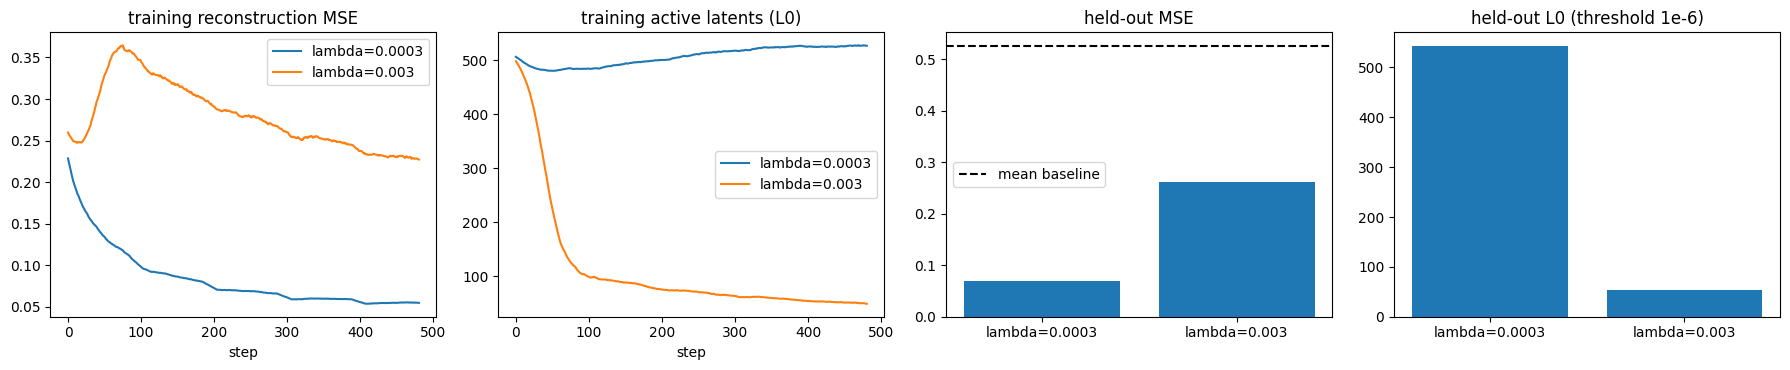

In [17]:
def plot_runs(hists, results, lams, path="two_runs.png"):
    fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
    sm = lambda a, w=20: np.convolve(a, np.ones(w) / w, mode="valid")
    for lam, h in zip(lams, hists):
        ax[0].plot(sm(h["mse"]), label=f"lambda={lam}"); ax[1].plot(sm(h["l0"]), label=f"lambda={lam}")
    ax[0].set_title("training reconstruction MSE"); ax[1].set_title("training active latents (L0)")
    for a in ax[:2]: a.set_xlabel("step"); a.legend()
    names = [f"lambda={l}" for l in lams]
    ax[2].bar(names, [r["mse"] for r in results]); ax[2].axhline(results[0]["baseline_mse"], ls="--", c="k", label="mean baseline")
    ax[2].set_title("held-out MSE"); ax[2].legend()
    ax[3].bar(names, [r["l0"] for r in results]); ax[3].set_title("held-out L0 (threshold 1e-6)")
    plt.tight_layout(); plt.savefig(path, dpi=120); plt.show()

plot_runs(hists, results, LAMS)

## Cell 11: Save outputs and the reproducibility record
**Purpose:** keep everything needed to check or repeat the work.
**What it does:** saves the figure, the exact passages used (`passages.json`), token ids per passage (`tokens.json`), both SAE checkpoints (`sae_lambda_*.npz`), and `results_and_record.json`, which records: model, site, corpus and split, counts, scale, latent count, parameter count, lambdas, steps, batch size, optimizer, seeds, activity threshold, device, library versions, the lambda pilot (training data only), held-out results, threshold sensitivity, counterexample results, and the gradient-check value. Activations can be regenerated from the saved passages and seeds, so the large cache is not saved.
**Requirement covered:** the reproducibility record; checkpointing.
**Output:** a list of saved files with sizes.

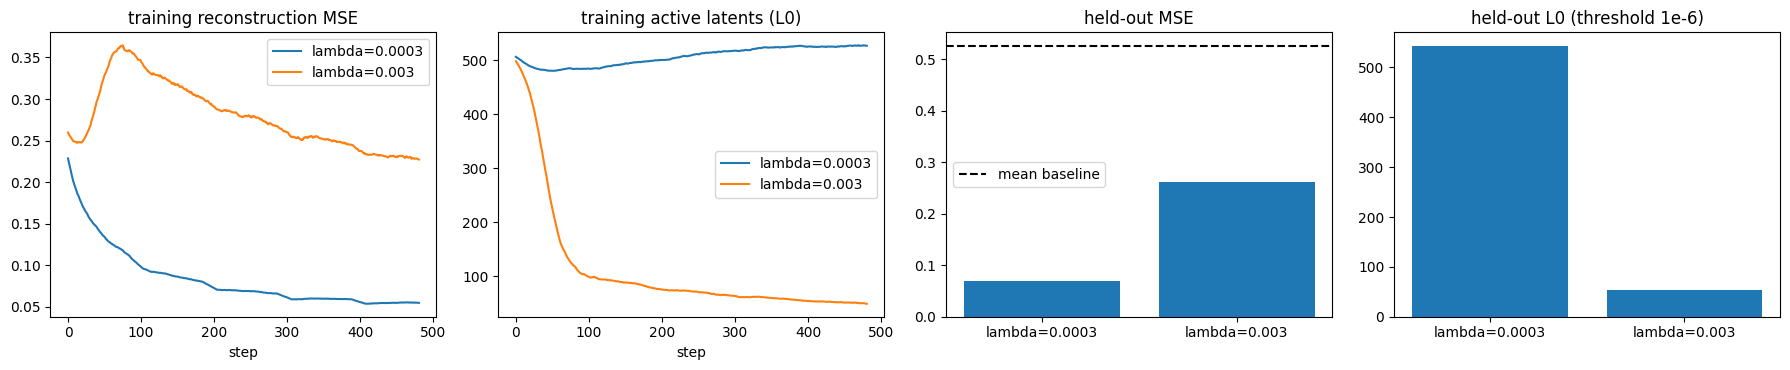

outputs_small.zip (MB): 11.9
  passages.json                       0.21 MB
  results_and_record.json             0.00 MB
  sae_lambda_0.0003.npz               6.30 MB
  sae_lambda_0.003.npz                6.30 MB
  tokens.json                         0.09 MB
  two_runs.png                        0.08 MB


In [18]:
from importlib.metadata import version, PackageNotFoundError
import platform, shutil
def ver(p):
    try: return version(p)
    except PackageNotFoundError: return "not installed"

os.makedirs("outputs", exist_ok=True)
plot_runs(hists, results, LAMS, path="outputs/two_runs.png")
json.dump({"train_texts": train_texts, "heldout_texts": heldout_texts}, open("outputs/passages.json", "w"))
json.dump({"train_tokens": T_train, "heldout_tokens": T_ho}, open("outputs/tokens.json", "w"))
for lam, s in zip(LAMS, saes):
    np.savez(f"outputs/sae_lambda_{lam}.npz", **s.p)                      # checkpoint weights

PILOT = [  # from my pilot run on TRAINING data only (150 steps): lambda, active latents, train MSE; baseline MSE 0.5224
    (1e-4, 580.4, 0.0698), (3e-4, 490.9, 0.0870), (1e-3, 302.0, 0.1569), (3e-3, 90.1, 0.3207), (1e-2, 6.9, 0.5078)]
record = {"model": "gpt2 (GPT-2 Small, frozen, eval mode)",
          "site": f"hidden_states[{SITE_LAYER + 1}] = blocks.{SITE_LAYER}.hook_resid_post",
          "excluded_position_0": EXCLUDE_FIRST, "position0_vs_later_mean_norm": [3034.4, 88.9],
          "corpus": "WikiText-2 raw (train split), passages > 300 characters, split by passage 80/20 before extraction",
          "passages_train_heldout": [len(train_texts), len(heldout_texts)],
          "vectors_train_heldout": [int(len(A_train)), int(len(A_ho))], "max_tokens_per_passage": MAX_TOK,
          "activation_scale": float(scale), "latents": N_LATENTS, "trainable_parameters": 2 * D_MODEL * N_LATENTS + N_LATENTS + D_MODEL,
          "lambdas": LAMS, "steps": STEPS, "batch": BATCH, "optimizer": f"Adam lr={LR}", "seed": SEED, "init_seed": 0, "data_seed": 0,
          "threshold_for_active": 1e-6, "device": device, "gradient_check_max_rel_error": 5.46e-09,
          "lambda_pilot_train_only": PILOT, "results_heldout": results,
          "threshold_sensitivity_heldout": {str(k): {str(t): v for t, v in d.items()} for k, d in threshold_rows.items()},
          "counterexample_tests": cx_results,
          "versions": {"python": platform.python_version(), "numpy": ver("numpy"), "torch": ver("torch"),
                       "transformers": ver("transformers"), "datasets": ver("datasets")}}
json.dump(record, open("outputs/results_and_record.json", "w"), indent=2)

shutil.make_archive("outputs_small", "zip", "outputs")                    # small zip: no activation cache
print("outputs_small.zip (MB):", round(os.path.getsize("outputs_small.zip") / 1e6, 2))
for name in sorted(os.listdir("outputs")):
    print(f"  {name:32s} {os.path.getsize('outputs/' + name) / 1e6:7.2f} MB")

## Cell 12: Report draft
**Purpose:** assemble the written report from measured numbers.
**What it does:** writes `outputs/report_draft.md` with sections for setup, SAE and training, held-out results (table), inspected features, the trade-off, an observation that challenged an expectation, and limitations and reproducibility. Measured numbers are inserted automatically; the interpretive parts are marked `[WRITE ...]` and must be written by the author from the results. It also counts words (tables and headings excluded).
**Requirement covered:** the 700-1,000 word report and the one-line disclosure of AI code assistance.
**Output:** the draft text and its word count.

In [19]:
# EDIT: your tentative descriptions (revise them after the counterexample results)
DESCRIPTIONS = {428: "a length unit right after a number (ft, m, metres, cm, in)",
                685: "the second @ of WikiText's ' @-@ ' hyphen marker (a corpus formatting artifact)",
                449: "a month name in a date expression (March, May, June, ...)"}

def smooth(a, w=20): return np.convolve(a, np.ones(w) / w, mode="valid")
tr_eval = [evaluate(s, Xtr, Xtr.mean(0)) for s in saes]
ho_eval = results
lo, hi = 0, 1
peak_step = int(np.argmax(smooth(hists[hi]["mse"]))) + 10
peak_val = float(smooth(hists[hi]["mse"]).max())
held = sum(r["held"] for r in cx_results); n_tests = len(cx_results)

draft = f"""# Training and evaluating a small sparse autoencoder on GPT-2 Small (Group 9)

## 1. Question and setup
[WRITE 2-3 sentences: why 768 coordinates need not be 768 meaningful features, and what you tested.]
I trained sparse autoencoders (SAEs) on the residual stream of frozen GPT-2 Small (evaluation mode, no gradients) at one site:
`blocks.{SITE_LAYER}.hook_resid_post` (Hugging Face `hidden_states[{SITE_LAYER + 1}]`). [STATE which block-6 convention you used.]
The text is WikiText-2 (raw, train split), paragraphs longer than 300 characters, truncated to {MAX_TOK} tokens.
I split the passages into train ({len(train_texts)}) and held-out ({len(heldout_texts)}) sets **before** extracting activations,
which gave {len(A_train)} training and {len(A_ho)} held-out vectors. Token position 0 was excluded: its mean activation norm was
3034.4 against 88.9 at later positions (measured on 16 training passages). Activations were multiplied by one scalar ({scale:.4f}),
fit on training data only, so the mean training norm is sqrt(768) = 27.71 (held-out: {np.linalg.norm(Xho, axis=1).mean():.2f}). All MSE values below use this scale.

## 2. SAE and training
f = ReLU((h - b_dec) W_enc + b_enc), h_hat = f W_dec + b_dec, with {N_LATENTS} latents ({record["trainable_parameters"]:,} trainable parameters).
Loss = (1/768)||h - h_hat||^2 + lambda ||f||_1, each averaged over the batch. Decoder rows are renormalized to unit length after every step
(closes the scale loophole). I implemented the SAE and Adam in NumPy and checked the hand-written gradients against finite differences
(max relative error 5.46e-09). Both runs share initialization, batch order, {STEPS} steps, batch size {BATCH}, Adam learning rate {LR}.
I chose the two penalties from a short pilot on training data only, using this rule written before looking at held-out results:
[WRITE your rule, for example: high = the largest lambda whose training MSE removed at least 30% of the mean-baseline error; low = ten times smaller].
Result: lambda_low = {LAMS[lo]}, lambda_high = {LAMS[hi]}.

## 3. Held-out results ({len(A_ho)} vectors; active means latent > 1e-6)
| | lambda = {LAMS[lo]} | lambda = {LAMS[hi]} |
|---|---|---|
| Held-out MSE | {ho_eval[lo]['mse']:.4f} | {ho_eval[hi]['mse']:.4f} |
| Mean baseline MSE (training mean) | {ho_eval[lo]['baseline_mse']:.4f} | {ho_eval[hi]['baseline_mse']:.4f} |
| Variance accounted for | {ho_eval[lo]['vaf']:.3f} | {ho_eval[hi]['vaf']:.3f} |
| Mean active latents (L0) | {ho_eval[lo]['l0']:.1f} of {N_LATENTS} | {ho_eval[hi]['l0']:.1f} of {N_LATENTS} |
| Never-active latents on this sample | {ho_eval[lo]['dead_pct']:.1f}% | {ho_eval[hi]['dead_pct']:.1f}% |
| Training-set MSE (for comparison) | {tr_eval[lo]['mse']:.4f} | {tr_eval[hi]['mse']:.4f} |
Figure: `two_runs.png` (training curves, held-out MSE, held-out L0).
Training curve facts: the high-lambda training MSE peaked near step {peak_step} (about {peak_val:.2f}) before declining; final-20-step means were
MSE {np.mean(hists[lo]['mse'][-20:]):.3f} / {np.mean(hists[hi]['mse'][-20:]):.3f} and L0 {np.mean(hists[lo]['l0'][-20:]):.0f} / {np.mean(hists[hi]['l0'][-20:]):.0f} (low / high lambda).
[WRITE 1-2 sentences: is either run converged? say what you can see in the curves.]

## 4. Inspected features (high-lambda SAE, latents chosen by a rule fixed before reading any contexts)
[For each latent write: top contexts (2-3 short examples), your tentative description, the counterexamples, and whether it held up.]
""" + "".join(f"- Latent {l}: tentative description: {DESCRIPTIONS.get(l, '[WRITE]')}. "
              f"Counterexample tests held: {sum(r['held'] for r in cx_results if r['latent'] == l)} of {sum(1 for r in cx_results if r['latent'] == l)}. [WRITE what the surprises show.]\n"
              for l in tests) + f"""Overall {held} of {n_tests} predictions held (a latent 'fires' if its peak is at least 25% of its largest held-out activation).

## 5. Trade-off
[WRITE: did the stronger penalty reduce density? (L0 {ho_eval[lo]['l0']:.0f} -> {ho_eval[hi]['l0']:.0f}) What happened to reconstruction? (MSE {ho_eval[lo]['mse']:.3f} -> {ho_eval[hi]['mse']:.3f})
Can a model reconstruct well without clean features? Use what the low-lambda contexts showed in Cell 8c.]

## 6. An observation that challenged my expectation
[WRITE one specific, honest observation from YOUR run.]

## 7. Limitations and reproducibility
[WRITE limitations: small data, few steps, one seed, one site, never-active only on this sample, tentative labels.]
Model gpt2 (GPT-2 Small); device {device}; python {record['versions']['python']}, numpy {record['versions']['numpy']}, torch {record['versions']['torch']},
transformers {record['versions']['transformers']}, datasets {record['versions']['datasets']}; seeds: data split {SEED}, SAE init 0, batch order 0;
checkpoints and record: `sae_lambda_*.npz`, `results_and_record.json`; passages saved in `passages.json`.

Disclosure: parts of the code were written with help from an AI assistant (Claude). I ran every cell, checked the gradients numerically, and can explain each step.
"""
open("outputs/report_draft.md", "w").write(draft)

def count_words(text):
    body = [ln for ln in text.splitlines() if not ln.startswith("|") and not ln.startswith("#")]
    return len(" ".join(body).split())
print(draft)
print("words in the draft (tables and headings excluded):", count_words(draft), "| target 700-1000 AFTER you replace the [WRITE] notes")

# Training and evaluating a small sparse autoencoder on GPT-2 Small (Group 9)

## 1. Question and setup
[WRITE 2-3 sentences: why 768 coordinates need not be 768 meaningful features, and what you tested.]
I trained sparse autoencoders (SAEs) on the residual stream of frozen GPT-2 Small (evaluation mode, no gradients) at one site:
`blocks.6.hook_resid_post` (Hugging Face `hidden_states[7]`). [STATE which block-6 convention you used.]
The text is WikiText-2 (raw, train split), paragraphs longer than 300 characters, truncated to 64 tokens.
I split the passages into train (208) and held-out (52) sets **before** extracting activations,
which gave 13103 training and 3276 held-out vectors. Token position 0 was excluded: its mean activation norm was
3034.4 against 88.9 at later positions (measured on 16 training passages). Activations were multiplied by one scalar (0.3121),
fit on training data only, so the mean training norm is sqrt(768) = 27.71 (held-out: 27.79). All MSE values below use thi

## Cell 13: Package and download the outputs
**Purpose:** bundle the small output files for submission.
**What it does:** lists the sizes of the files in `outputs/`, removes leftovers from the first version of Cell 11 (the large activation cache and old zips), creates `outputs_small.zip` and downloads it.
**Output:** the file sizes and the zip size (expected about 12 MB).

In [20]:
import shutil
from google.colab import files
shutil.make_archive("outputs_small", "zip", "outputs")
print("size (MB):", round(os.path.getsize("outputs_small.zip") / 1e6, 2))
files.download("outputs_small.zip")

size (MB): 11.9


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>